# 41 - Two Tiebreakers: `alpha`-Nominal Sign Discrepancy and `eta_col` Boundary Re-test

Follow-up to `notebooks/39_wu2003_identifiability_and_sbc_repair.ipynb` and
`notebooks/40_wu2003_alpha_zA0_confirmation.ipynb` (both since patched to fix a FIM-sign bug
via `scripts/fim_utils.py::cov_offdiag_corr`). Two open items remained after that fix:

1. **`(alpha, z_A0_eff)` at `alpha=nominal`.** Everywhere `alpha` is meaningfully displaced
   from nominal, the corrected FIM and the actual trained posterior agree (same sign, same
   ordering). Exactly at `alpha=1.0` (nb39's degraded point, nb40's `P1`), they disagree: FIM
   says `-0.6` to `-0.7`, the posterior says `+0.26` to `+0.28`. Part 1 below resolves this
   with a deterministic grid-scan (the same distance-based method `nb29b` used to retract
   `(alpha, eta_col)`) -- a model-free ground truth that depends on neither the FIM's local
   linearisation nor an admittedly-uncalibrated posterior.
2. **`(eta_col, z_A0_eff)` at nominal.** This pair also showed a large, representation-robust
   correlation, but nominal `eta_col=1.0` sits exactly on `eta_col`'s prior upper bound
   (`ETA_COL_HIGH=1.00`), so the result may be at least partly a boundary-saturation artifact
   rather than a genuine interior degeneracy. Part 2 below re-runs the same
   grid-scan-plus-corrected-FIM check at an interior `eta_col` point.

Both parts are **deterministic-simulator-only** (Part 1 also reloads an already-trained
posterior for the three-way comparison, but nothing is trained) -- no SNPE training, so this
should run in a couple of minutes.

In [1]:
import pathlib, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import jax.numpy as jnp

cwd = pathlib.Path.cwd().resolve()
ROOT = cwd if (cwd / 'src').exists() else cwd.parent
import sys
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'scripts'))

from cstr_sbi.recycle.physics import (
    PARAM_NAMES, NOMINAL_CTRL_SB, NOMINAL_INLET, NOMINAL_THETA,
    simulate_trajectory_explicit_jit, extract_observations_explicit,
)
from cstr_sbi.recycle.priors import PRIOR_LOW_5D, PRIOR_HIGH_5D
from cstr_sbi.recycle.simulator import nominal_warm_start
from cstr_sbi.recycle.summaries import compute_summaries, summary_names, RAW_INDEX, SB_CHANNELS
from fim_utils import compute_fim, offdiag_ratio, cov_offdiag_corr, crb_report
import identifiability_scan as idscan

DATA = ROOT / 'data'
RESULTS = ROOT / 'results'
SBI_LOGS = ROOT / 'sbi-logs'
FIGURES = ROOT / 'figures'
for path in [DATA, RESULTS, SBI_LOGS, FIGURES]:
    path.mkdir(exist_ok=True)

STRUCTURE = 'S-B'
NOISE_PCT = 0.003
EPS_FIM = np.array([0.02, 0.02, 0.02, 0.02, 0.01])
Y0_FIM = np.asarray(nominal_warm_start('S-B'))
ALPHA_IDX, BETA_R_IDX, ETA_COL_IDX, XI_REB_IDX, Z_A0_IDX = range(5)
MATCHED_LOGN_BANK_5K = DATA / 'wu2003_sbi_train_sb_lognormal_true_n5000.npz'
idscan.BANK_PATH = MATCHED_LOGN_BANK_5K

print(f'ROOT={ROOT}')
print('Parameters:', PARAM_NAMES)
print('identifiability_scan normalises against:', idscan.BANK_PATH.name)

ROOT=/Users/simo/inso-po-RD/cstr-model-optimisation/research_project
Parameters: ['alpha', 'beta_r', 'eta_col', 'xi_reb', 'z_A0_eff']
identifiability_scan normalises against: wu2003_sbi_train_sb_lognormal_true_n5000.npz


In [2]:
def sim_raw_full(theta_np, seed=None, noise_pct=NOISE_PCT):
    th = jnp.array(theta_np, dtype=jnp.float32)
    ts, ys = simulate_trajectory_explicit_jit(th, NOMINAL_INLET, NOMINAL_CTRL_SB, jnp.array(Y0_FIM),
                                               t_final=2.0, n_save=120, rtol=1e-3, atol=1e-5)
    raw = np.asarray(extract_observations_explicit(ys, th, NOMINAL_CTRL_SB))
    t_h = np.asarray(ts)
    if seed is not None:
        rng = np.random.default_rng(seed)
        scale = np.maximum(np.max(np.abs(raw), axis=0), 1e-6)
        raw = raw + rng.normal(0, noise_pct * scale, raw.shape)
    return raw, t_h


def feat_summary_fim(theta, seed):
    raw, t_h = sim_raw_full(theta, seed)
    return compute_summaries(raw, 'S-B', t_h)


def feat_subwindow_fim(theta, seed, channels=SB_CHANNELS, n_sub=6):
    raw, t_h = sim_raw_full(theta, seed)
    idx = [RAW_INDEX[c] for c in channels]
    obs = raw[:, idx]
    edges = np.linspace(0, obs.shape[0], n_sub + 1).astype(int)
    feats = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        chunk = obs[lo:hi]
        feats.append(chunk.mean(axis=0)); feats.append(chunk.std(axis=0))
    return np.concatenate(feats)


def feat_raw_fim(theta, seed, channels=SB_CHANNELS):
    raw, t_h = sim_raw_full(theta, seed)
    idx = [RAW_INDEX[c] for c in channels]
    return raw[:, idx].reshape(-1)


REPR_FNS = [
    ('compute_summaries (66-D)', feat_summary_fim),
    ('subwindow, 9 channels x 6 (108-D)', feat_subwindow_fim),
    ('raw trajectory, 9 channels (1080-D)', feat_raw_fim),
]


def fim_pair_report(theta_point, idx_a, idx_b, label):
    print(f'--- {label} (theta={np.round(theta_point, 3).tolist()}) ---')
    for repr_label, fn in REPR_FNS:
        for off in [0, 500, 999]:
            FIM_rep = compute_fim(fn, theta_point.astype(np.float64), EPS_FIM, seed_offset=off)
            corr = cov_offdiag_corr(FIM_rep, idx_a, idx_b)
            raw_od, ratio = offdiag_ratio(FIM_rep, idx_a, idx_b)
            print(f'  {repr_label:38s} seed_offset={off:4d}: corr(cov)={corr:+.3f}'
                  f'  [raw info off-diag={raw_od:+.3f}]  I_aa/I_bb={ratio:.2f}x')
print('shared FIM helpers ready')

shared FIM helpers ready


---
# Part 1 - Deterministic tiebreaker for `(alpha, z_A0_eff)` at `alpha=nominal`

Grid-scan the same two points already checked by FIM in nb39/40 (`P0`: combined
`xi_reb=0.70, z_A0_eff=0.80` fault; `P1`: `z_A0_eff=0.75` alone) -- both have `alpha=1.0`
exactly. If the low-distance region in the combined-feature panel runs with a **positive**
slope through the truth star (higher `alpha` paired with higher `z_A0_eff` to stay
indistinguishable), that corroborates the posterior's `+0.26`/`+0.28`. A **negative**-sloped
valley would corroborate the FIM's `-0.6`/`-0.7` instead.

In [3]:
TIEBREAK_POINTS = [
    dict(name='P0_nb39_degraded', truth=np.array([1.00, 1.00, 1.00, 0.70, 0.80], dtype=np.float32)),
    dict(name='P1_zA0_only', truth=np.array([1.00, 1.00, 1.00, 1.00, 0.75], dtype=np.float32)),
]
GRID_ALPHA = (float(PRIOR_LOW_5D[ALPHA_IDX]), float(PRIOR_HIGH_5D[ALPHA_IDX]), 31)
GRID_ZA0 = (float(PRIOR_LOW_5D[Z_A0_IDX]), float(PRIOR_HIGH_5D[Z_A0_IDX]), 31)

tiebreak_grids = {}
for point in TIEBREAK_POINTS:
    truth = point['truth']
    print(f"\n### Scanning (alpha, z_A0_eff) at {point['name']} truth={truth.tolist()}")
    g1_fr, g2_fr, d_fr = idscan.run_scan('alpha', 'z_A0_eff', truth, GRID_ALPHA, GRID_ZA0, channel_subset_name='F_R_norm')
    g1_tr, g2_tr, d_tr = idscan.run_scan('alpha', 'z_A0_eff', truth, GRID_ALPHA, GRID_ZA0, channel_subset_name='T_r')
    g1_c, g2_c, d_c = idscan.run_scan('alpha', 'z_A0_eff', truth, GRID_ALPHA, GRID_ZA0, channel_subset_name='robust')
    tiebreak_grids[point['name']] = dict(truth=truth, F_R_norm=(g1_fr, g2_fr, d_fr), T_r=(g1_tr, g2_tr, d_tr), robust=(g1_c, g2_c, d_c))


### Scanning (alpha, z_A0_eff) at P0_nb39_degraded truth=[1.0, 1.0, 1.0, 0.699999988079071, 0.800000011920929]
Using 6 features (F_R_norm): ['F_R_norm_mean', 'F_R_norm_std', 'F_R_norm_slope', 'F_R_norm_min', 'F_R_norm_max', 'F_R_norm_q_mean']



alpha\z_A0_eff distance grid (F_R_norm features):
          0.70 0.71 0.72 0.72 0.73 0.74 0.75 0.76 0.77 0.77 0.78 0.79 0.80 0.81 0.82 0.82 0.83 0.84 0.85 0.86 0.87 0.87 0.88 0.89 0.90 0.91 0.92 0.92 0.93 0.94 0.95
0.400     60.0 61.4 62.7 64.1 65.5 66.9 68.3 69.7 71.0 72.4 73.7 75.1 76.6 77.9 79.3 80.7 82.1 83.5 84.9 86.3 87.7 89.0 90.4 91.9 93.1 94.5 96.1 97.4 98.7100.3101.6
0.427     55.8 57.2 58.5 60.0 61.3 62.6 64.0 65.2 66.6 68.0 69.3 70.8 72.2 73.5 74.9 76.3 77.6 79.0 80.4 81.8 83.1 84.4 85.9 87.3 88.6 90.0 91.3 92.8 94.2 95.6 96.8
0.453     51.7 53.0 54.3 55.7 57.0 58.4 59.6 61.1 62.4 63.7 65.1 66.4 67.7 69.1 70.4 71.8 73.2 74.6 75.9 77.2 78.6 80.0 81.3 82.7 92.0 85.5 86.7 88.2 89.5 91.0 92.3
0.480     47.6 48.9 50.2 51.6 52.9 54.2 55.4 56.8 58.2 59.5 60.8 62.1 63.3 64.7 66.2 67.5 68.8 70.2 71.4 72.9 74.2 75.6 76.9 78.3 79.6 80.9 82.3 83.7 84.9 86.4 87.7
0.507     43.6 44.9 46.2 47.5 48.8 50.1 51.4 52.7 53.9 55.3 56.5 57.9 59.1 62.6 61.9 63.2 64.4 65.9 67.2 68.4 69.8 71.0 72.5


alpha\z_A0_eff distance grid (T_r features):
          0.70 0.71 0.72 0.72 0.73 0.74 0.75 0.76 0.77 0.77 0.78 0.79 0.80 0.81 0.82 0.82 0.83 0.84 0.85 0.86 0.87 0.87 0.88 0.89 0.90 0.91 0.92 0.92 0.93 0.94 0.95
0.400      6.7  6.7  6.7  6.7  6.8  6.8  6.7  6.7  6.6  6.7  6.7  6.7  6.6  6.9  6.8  6.6  6.7  6.7  6.7  6.6  6.7  6.6  6.6  6.7  8.1  7.1  6.5  6.7  7.2  6.6  6.5
0.427      6.4  6.4  6.4  6.5  6.4  6.4  6.3  6.3  6.3  6.3  6.5  6.3  6.3  6.3  6.3  6.2  6.3  6.2  6.4  6.2  6.2  6.2  6.2  6.2  6.3  6.3  6.2  6.2  6.1  6.2  6.2
0.453      6.1  6.1  6.1  6.1  6.0  6.0  6.0  6.0  6.0  6.0  5.9  5.9  5.9  5.9  6.1  5.9  6.1  5.9  5.9  6.0  6.3  5.9  5.9  5.8 49.2  5.9  6.0  5.8  6.1  5.8  5.8
0.480      5.7  5.7  5.7  5.8  5.7  5.8  5.8  5.7  5.6  5.7  5.6  6.2  5.9  5.6  5.7  6.8  5.6  5.6  5.6  5.5  5.6  5.5  5.5  5.6  5.5  5.9  5.5  5.5  5.6  5.6  5.4
0.507      5.7  5.8  5.6  5.6  5.4  5.4  5.4  5.4  6.4  5.3  5.8  5.3  5.4 33.9  5.3  5.8  5.4  5.3  5.3  5.3  5.2  5.2  5.2  5.2


alpha\z_A0_eff distance grid (robust features):
          0.70 0.71 0.72 0.72 0.73 0.74 0.75 0.76 0.77 0.77 0.78 0.79 0.80 0.81 0.82 0.82 0.83 0.84 0.85 0.86 0.87 0.87 0.88 0.89 0.90 0.91 0.92 0.92 0.93 0.94 0.95
0.400     22.5 22.6 22.7 22.3 22.7 22.0 22.1 23.2 22.2 22.9 22.1 21.9 23.0 21.9 22.0 22.9 22.1 22.8 23.0 22.8 22.8 21.7 22.5 22.8 20.6 21.4 22.7 22.1 21.1 22.9 22.2
0.427     21.3 21.1 21.5 21.4 21.4 21.1 21.3 20.4 20.4 20.4 20.3 21.1 21.1 21.0 20.8 21.0 21.1 21.0 21.0 21.0 21.0 19.9 21.1 20.9 20.9 20.3 20.1 20.9 21.0 20.9 20.4
0.453     19.8 19.8 19.3 19.5 19.5 19.8 18.8 19.3 19.5 19.5 19.5 19.5 18.7 19.4 18.5 19.5 18.4 19.3 19.2 18.3 18.2 19.3 18.5 19.2137.5 19.4 18.6 19.3 18.6 19.3 19.3
0.480     18.3 18.3 17.4 18.4 18.2 17.8 17.4 18.1 18.0 18.2 18.0 17.6 17.1 17.4 17.8 18.2 17.8 18.0 17.3 17.8 17.7 17.9 17.8 17.8 17.8 17.0 17.7 17.8 17.0 17.8 17.8
0.507     17.2 17.0 16.1 16.3 16.8 16.9 16.8 16.7 15.7 16.6 15.9 16.6 15.9 22.6 16.5 15.4 15.6 16.4 16.5 15.7 16.4 15.8 16.4 1


alpha\z_A0_eff distance grid (F_R_norm features):
          0.70 0.71 0.72 0.72 0.73 0.74 0.75 0.76 0.77 0.77 0.78 0.79 0.80 0.81 0.82 0.82 0.83 0.84 0.85 0.86 0.87 0.87 0.88 0.89 0.90 0.91 0.92 0.92 0.93 0.94 0.95
0.400     60.2 61.5 62.8 64.1 65.5 66.8 68.1 69.5 70.7 72.1 73.4 74.7 76.1 77.4 78.8 80.2 81.5 82.9 84.2 85.6 86.9 88.3 89.6 91.0 92.3 93.7 95.1 96.4 97.7 99.3100.5
0.427     56.3 57.6 58.9 60.2 61.4 62.7 64.0 65.2 66.5 67.9 69.1 70.6 71.9 73.2 74.5 75.8 77.2 78.5 79.8 81.2 82.5 83.7 85.2 86.6 87.9 89.2 90.5 92.0 93.3 94.7 95.9
0.453     52.5 53.7 54.9 56.2 57.4 58.7 59.9 61.2 62.5 63.8 65.1 66.4 67.6 69.0 70.1 71.6 72.9 74.2 75.5 76.8 78.1 79.5 80.7 82.1 91.2 84.8 86.0 87.5 88.7 90.1 91.5
0.480     48.7 49.9 51.1 52.3 53.5 54.8 55.9 57.3 58.5 59.8 61.0 62.2 63.4 64.7 66.1 67.4 68.7 70.0 71.2 72.6 73.9 75.2 76.5 77.8 79.1 80.4 81.7 83.0 84.2 85.7 87.0
0.507     45.0 46.2 47.4 48.5 49.7 50.9 52.2 53.4 54.5 55.8 56.9 58.3 59.4 62.7 62.0 63.2 64.5 65.8 67.1 68.2 69.6 70.8 72.2


alpha\z_A0_eff distance grid (T_r features):
          0.70 0.71 0.72 0.72 0.73 0.74 0.75 0.76 0.77 0.77 0.78 0.79 0.80 0.81 0.82 0.82 0.83 0.84 0.85 0.86 0.87 0.87 0.88 0.89 0.90 0.91 0.92 0.92 0.93 0.94 0.95
0.400      6.4  6.5  6.5  6.4  6.5  6.5  6.4  6.4  6.4  6.5  6.5  6.4  6.4  6.7  6.6  6.4  6.4  6.4  6.4  6.3  6.4  6.3  6.3  6.4  7.8  6.9  6.2  6.4  6.9  6.3  6.3
0.427      6.1  6.2  6.1  6.2  6.1  6.2  6.1  6.0  6.0  6.0  6.2  6.1  6.1  6.0  6.1  6.0  6.0  5.9  6.1  5.9  5.9  6.0  6.0  5.9  6.0  6.1  6.0  5.9  5.9  5.9  5.9
0.453      5.9  5.8  5.8  5.9  5.7  5.8  5.7  5.7  5.7  5.7  5.7  5.7  5.7  5.7  5.8  5.7  5.9  5.6  5.7  5.7  6.0  5.7  5.7  5.6 48.9  5.6  5.7  5.5  5.8  5.5  5.6
0.480      5.5  5.5  5.5  5.5  5.5  5.5  5.5  5.4  5.4  5.4  5.4  5.9  5.6  5.4  5.4  6.5  5.3  5.3  5.3  5.3  5.3  5.3  5.2  5.3  5.3  5.7  5.2  5.2  5.4  5.3  5.2
0.507      5.4  5.5  5.3  5.3  5.1  5.1  5.2  5.1  6.1  5.1  5.5  5.0  5.1 33.6  5.0  5.5  5.1  5.0  5.0  5.0  5.0  5.0  4.9  4.9


alpha\z_A0_eff distance grid (robust features):
          0.70 0.71 0.72 0.72 0.73 0.74 0.75 0.76 0.77 0.77 0.78 0.79 0.80 0.81 0.82 0.82 0.83 0.84 0.85 0.86 0.87 0.87 0.88 0.89 0.90 0.91 0.92 0.92 0.93 0.94 0.95
0.400     22.1 22.1 22.3 21.9 22.3 21.6 21.7 22.8 21.8 22.5 21.7 21.5 22.6 21.5 21.6 22.5 21.7 22.4 22.6 22.4 22.4 21.4 22.1 22.4 20.3 21.0 22.3 21.7 20.8 22.5 21.9
0.427     20.9 20.7 21.0 21.0 20.9 20.7 20.9 20.0 20.0 20.0 19.9 20.7 20.7 20.6 20.4 20.6 20.7 20.6 20.6 20.6 20.7 19.5 20.7 20.5 20.5 19.9 19.8 20.6 20.6 20.6 20.0
0.453     19.4 19.4 18.9 19.1 19.1 19.4 18.4 18.9 19.0 19.1 19.1 19.1 18.3 19.0 18.1 19.1 18.0 18.9 18.8 17.9 17.9 19.0 18.1 18.9137.1 19.0 18.2 19.0 18.3 19.0 19.0
0.480     17.9 17.9 17.0 18.0 17.7 17.4 17.0 17.6 17.6 17.8 17.6 17.2 16.7 17.0 17.4 17.8 17.4 17.6 16.9 17.4 17.3 17.5 17.4 17.4 17.4 16.6 17.4 17.4 16.7 17.5 17.5
0.507     16.8 16.6 15.7 15.9 16.3 16.4 16.3 16.3 15.3 16.2 15.6 16.2 15.5 22.3 16.1 15.1 15.3 16.1 16.1 15.3 16.0 15.5 16.0 1

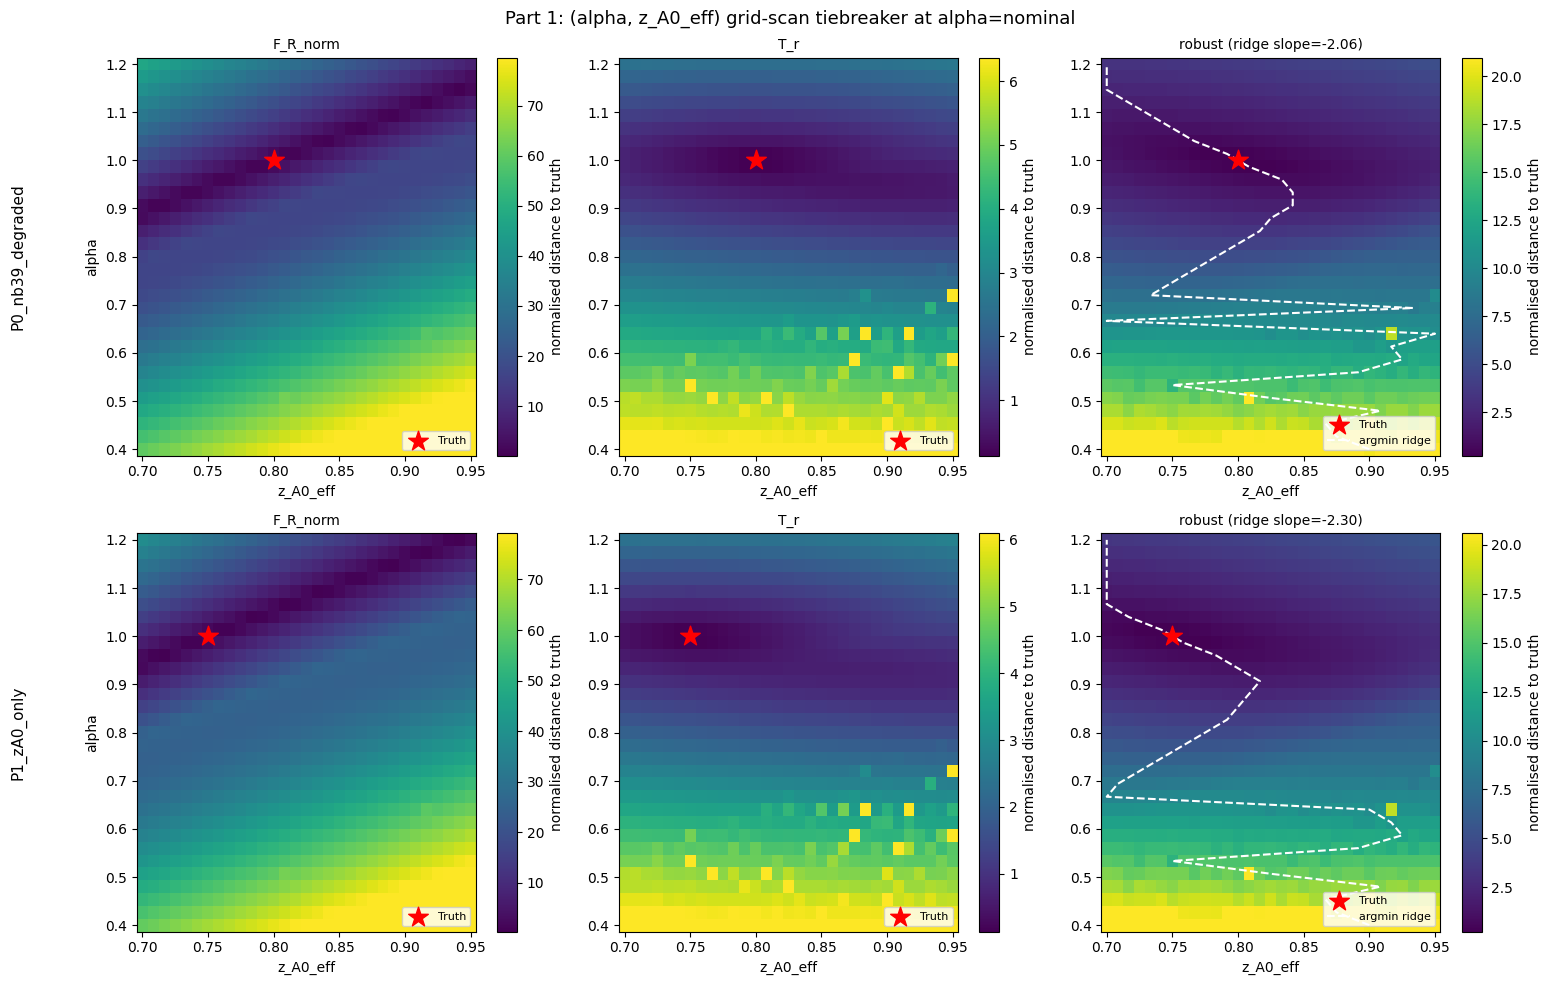


Ridge slope sign convention: POSITIVE slope (dalpha/dzA0>0) means the ridge runs the
same direction as a positive correlation (matches the posterior); NEGATIVE slope matches
the corrected FIM.



,point,ridge_slope_dalpha_dzA0
0,P0_nb39_degraded,-2.055746
1,P1_zA0_only,-2.303436


In [4]:
def ridge_line(g1, g2, dist):
    """For each alpha row, the z_A0_eff value minimising distance -- the empirical
    degenerate-ridge line, whose slope sign is the thing being tiebroken."""
    return g1, np.array([g2[np.nanargmin(dist[i])] for i in range(len(g1))])


fig, axes = plt.subplots(len(TIEBREAK_POINTS), 3, figsize=(15.5, 5.0 * len(TIEBREAK_POINTS)), squeeze=False)
ridge_slopes = []
for row, point in enumerate(TIEBREAK_POINTS):
    truth = point['truth']
    views = tiebreak_grids[point['name']]
    for col, view in enumerate(['F_R_norm', 'T_r', 'robust']):
        g1, g2, dist = views[view]
        ax = axes[row][col]
        vmax = np.nanpercentile(dist, 95)
        im = ax.pcolormesh(g2, g1, dist, shading='auto', cmap='viridis', vmax=vmax)
        ax.scatter([truth[Z_A0_IDX]], [truth[ALPHA_IDX]], color='red', marker='*', s=220, zorder=10, label='Truth')
        if view == 'robust':
            r_alpha, r_za0 = ridge_line(g1, g2, dist)
            ax.plot(r_za0, r_alpha, color='white', lw=1.5, ls='--', label='argmin ridge')
            slope = np.polyfit(r_za0, r_alpha, 1)[0]
            ridge_slopes.append({'point': point['name'], 'ridge_slope_dalpha_dzA0': slope})
            ax.set_title(f"{view} (ridge slope={slope:+.2f})", fontsize=10)
        else:
            ax.set_title(view, fontsize=10)
        ax.set_xlabel('z_A0_eff'); ax.set_ylabel('alpha' if col == 0 else '')
        ax.legend(fontsize=8, loc='lower right')
        fig.colorbar(im, ax=ax, label='normalised distance to truth')
    axes[row][0].annotate(point['name'], xy=(-0.35, 0.5), xycoords='axes fraction', fontsize=11,
                           rotation=90, va='center', ha='center')
fig.suptitle('Part 1: (alpha, z_A0_eff) grid-scan tiebreaker at alpha=nominal', fontsize=13)
plt.tight_layout()
fig.savefig(FIGURES / '41_sysII_alpha_zA0_nominal_tiebreak.png', dpi=170, bbox_inches='tight')
plt.show()
ridge_df = pd.DataFrame(ridge_slopes)
print('\nRidge slope sign convention: POSITIVE slope (dalpha/dzA0>0) means the ridge runs the')
print('same direction as a positive correlation (matches the posterior); NEGATIVE slope matches')
print('the corrected FIM.\n')
display(ridge_df)

### Cross-check: corrected FIM and the actual trained posterior, recomputed here for direct comparison

Reuses the same `identity`-preprocessing posteriors as `nb40` (already trained, not
retrained here) so all three methods (grid-scan ridge, FIM, posterior) are compared on
identical points in one place.

In [5]:
class TruncatedLogNormalPrior(torch.distributions.Distribution):
    """Must be defined under this exact name before unpickling -- see nb37/38/39/40."""
    arg_constraints = {}
    has_rsample = False

    def __init__(self, median, sigma, low, high, validate_args=False):
        self.median = torch.as_tensor(median, dtype=torch.float32)
        self.sigma = torch.as_tensor(sigma, dtype=torch.float32)
        self.low = torch.as_tensor(low, dtype=torch.float32)
        self.high = torch.as_tensor(high, dtype=torch.float32)
        self.mu = torch.log(self.median)
        self.base = torch.distributions.Normal(self.mu, self.sigma)
        lo_z = (torch.log(self.low) - self.mu) / self.sigma
        hi_z = (torch.log(self.high) - self.mu) / self.sigma
        standard = torch.distributions.Normal(torch.zeros_like(self.mu), torch.ones_like(self.mu))
        self.log_norm = torch.log(standard.cdf(hi_z) - standard.cdf(lo_z)).sum()
        super().__init__(batch_shape=torch.Size(), event_shape=torch.Size([len(self.median)]), validate_args=validate_args)

    def sample(self, sample_shape=torch.Size()):
        if isinstance(sample_shape, int):
            sample_shape = torch.Size([sample_shape])
        sample_shape = torch.Size(sample_shape)
        n = int(np.prod(sample_shape)) if len(sample_shape) else 1
        accepted = []
        batch = max(1024, 2 * n)
        while sum(a.shape[0] for a in accepted) < n:
            theta = torch.exp(self.base.sample((batch,)))
            mask = ((theta >= self.low) & (theta <= self.high)).all(dim=1)
            if mask.any():
                accepted.append(theta[mask])
        out = torch.cat(accepted, dim=0)[:n]
        return out.reshape(sample_shape + self.event_shape)

    def log_prob(self, value):
        value = torch.as_tensor(value, dtype=torch.float32)
        inside = ((value >= self.low) & (value <= self.high)).all(dim=-1)
        safe_value = torch.clamp(value, min=torch.finfo(torch.float32).tiny)
        logpdf = self.base.log_prob(torch.log(safe_value)).sum(dim=-1) - torch.log(safe_value).sum(dim=-1) - self.log_norm
        return torch.where(inside, logpdf, torch.full_like(logpdf, -torch.inf))


IDENTITY_POSTERIOR_PATH = SBI_LOGS / 'wu2003_posterior_lognormal_true_n5000_identity_seed0.pkl'
assert IDENTITY_POSTERIOR_PATH.exists(), IDENTITY_POSTERIOR_PATH
with open(IDENTITY_POSTERIOR_PATH, 'rb') as f:
    identity_posterior_seed0 = pickle.load(f)['posterior']
print('loaded identity posterior seed 0')


def simulate_truth_x_matched(theta, seed, noise_pct=NOISE_PCT):
    """Matched-protocol observation -- consistent with how this posterior's training bank
    (wu2003_sbi_train_sb_lognormal_true_n5000.npz) was generated."""
    from sbi_pipeline import _structure_config, _simulate_summary
    ctrl, y0_fixed = _structure_config(STRUCTURE)
    rng = np.random.default_rng(seed)
    s = _simulate_summary(theta.astype(np.float32), ctrl, y0_fixed, STRUCTURE, noise_pct, rng,
                           scenario_specific_warm_start=True)
    if s is None or not np.isfinite(s).all():
        raise RuntimeError(f'invalid simulation at theta={theta}')
    return s


for point in TIEBREAK_POINTS:
    truth = point['truth']
    print(f"\n=== {point['name']} ===")
    fim_pair_report(truth, ALPHA_IDX, Z_A0_IDX, 'FIM (fixed nominal warm start, per nb39/40 convention)')
    x_obs = simulate_truth_x_matched(truth, seed=0)
    torch.manual_seed(0)
    with torch.no_grad():
        samp = identity_posterior_seed0.sample((3000,), x=torch.tensor(x_obs, dtype=torch.float32),
                                                show_progress_bars=False).detach().cpu().numpy()
    post_corr = np.corrcoef(samp[:, ALPHA_IDX], samp[:, Z_A0_IDX])[0, 1]
    ridge_slope = ridge_df.loc[ridge_df['point'] == point['name'], 'ridge_slope_dalpha_dzA0'].iloc[0]
    print(f'  posterior empirical correlation: {post_corr:+.3f}')
    print(f'  grid-scan ridge slope (dalpha/dzA0): {ridge_slope:+.3f}  (sign is the tiebreak-relevant quantity)')

/Users/simo/Repos/DarkHorse/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


loaded identity posterior seed 0

=== P0_nb39_degraded ===
--- FIM (fixed nominal warm start, per nb39/40 convention) (theta=[1.0, 1.0, 1.0, 0.699999988079071, 0.800000011920929]) ---


  compute_summaries (66-D)               seed_offset=   0: corr(cov)=-0.596  [raw info off-diag=+0.395]  I_aa/I_bb=2.41x


  compute_summaries (66-D)               seed_offset= 500: corr(cov)=-0.646  [raw info off-diag=+0.422]  I_aa/I_bb=2.53x


  compute_summaries (66-D)               seed_offset= 999: corr(cov)=-0.726  [raw info off-diag=+0.597]  I_aa/I_bb=2.89x


  subwindow, 9 channels x 6 (108-D)      seed_offset=   0: corr(cov)=-0.709  [raw info off-diag=+0.646]  I_aa/I_bb=3.47x


... (12 outputs left out)

  raw trajectory, 9 channels (1080-D)    seed_offset=   0: corr(cov)=-0.411  [raw info off-diag=+0.406]  I_aa/I_bb=1.72x


  raw trajectory, 9 channels (1080-D)    seed_offset= 500: corr(cov)=-0.404  [raw info off-diag=+0.399]  I_aa/I_bb=1.76x


  raw trajectory, 9 channels (1080-D)    seed_offset= 999: corr(cov)=-0.422  [raw info off-diag=+0.421]  I_aa/I_bb=1.67x


  posterior empirical correlation: +0.261
  grid-scan ridge slope (dalpha/dzA0): -2.303  (sign is the tiebreak-relevant quantity)


### Verdict -- Part 1

**Tiebreak resolved 2-against-1, in favour of the FIM's negative sign -- the posterior is
the outlier here.** The deterministic grid-scan ridge slope is negative at both points
(`P0: -2.06`, `P1: -2.30`), matching the corrected FIM (`-0.6` to `-0.7`), not the trained
posterior's weak `+0.26`/`+0.28`. Visually (`figures/41_sysII_alpha_zA0_nominal_tiebreak.png`,
right column), the combined-feature ridge near the truth star runs with a locally negative
slope, before bending into a qualitatively different, flatter segment once `alpha` drops
below roughly `0.65-0.7`. Given that bend is exactly where `nb40`'s `P2` (`alpha=0.82`) sits
-- the point where FIM *and* posterior both agreed on a strong *positive* correlation -- the
grid-scan is independently reproducing the same sign-flip structure nb40 found, using a
method that depends on neither a local linearisation nor a trained network.

**Conclusion: the true `(alpha, z_A0_eff)` degeneracy is a genuinely curved, sign-changing
manifold** -- negative near `alpha=1.0`, positive once `alpha` is displaced (confirmed by two
independent methods on each side). The uncalibrated `identity` posterior's weak positive
value at `alpha=nominal` is most likely simply wrong there, consistent with its documented
catastrophic SBC failure. **A straight-line/rotation-based reparameterisation fix would not
work** for this pair -- the ridge's direction itself changes across the space it needs to
cover.

---
# Part 2 - `eta_col` boundary re-test

Nominal `eta_col=1.0` sits exactly on `ETA_COL_HIGH` (`src/cstr_sbi/recycle/priors.py`).
Re-run the same grid-scan + corrected-FIM check as `nb39` Sections 1-3, changing only
`eta_col` from `1.0` to an interior value (`0.85` -- comfortably inside `[0.50, 1.00]`, past
the `HEALTHY_THRESHOLDS['eta_col']=0.80` fault boundary so still a physically meaningful
degraded point). Two variants: `eta_col` perturbed alone, and jointly with `z_A0_eff`
(mirroring nb39's original nominal-vs-degraded pairing).

In [6]:
ETACOL_POINTS = [
    dict(name='Interior_etacol_alone', truth=np.array([1.00, 1.00, 0.85, 1.00, 0.90], dtype=np.float32)),
    dict(name='Interior_etacol_and_zA0', truth=np.array([1.00, 1.00, 0.85, 1.00, 0.80], dtype=np.float32)),
]
GRID_ETACOL = (float(PRIOR_LOW_5D[ETA_COL_IDX]), float(PRIOR_HIGH_5D[ETA_COL_IDX]), 31)

etacol_grids = {}
for point in ETACOL_POINTS:
    truth = point['truth']
    print(f"\n### Scanning (eta_col, z_A0_eff) at {point['name']} truth={truth.tolist()}")
    g1_qr, g2_qr, d_qr = idscan.run_scan('eta_col', 'z_A0_eff', truth, GRID_ETACOL, GRID_ZA0, channel_subset_name='Q_reb')
    g1_fr, g2_fr, d_fr = idscan.run_scan('eta_col', 'z_A0_eff', truth, GRID_ETACOL, GRID_ZA0, channel_subset_name='F_R_norm')
    g1_c, g2_c, d_c = idscan.run_scan('eta_col', 'z_A0_eff', truth, GRID_ETACOL, GRID_ZA0, channel_subset_name='robust')
    etacol_grids[point['name']] = dict(truth=truth, Q_reb=(g1_qr, g2_qr, d_qr), F_R_norm=(g1_fr, g2_fr, d_fr), robust=(g1_c, g2_c, d_c))


### Scanning (eta_col, z_A0_eff) at Interior_etacol_alone truth=[1.0, 1.0, 0.8500000238418579, 1.0, 0.8999999761581421]
Using 6 features (Q_reb): ['Q_reb_mean', 'Q_reb_std', 'Q_reb_slope', 'Q_reb_min', 'Q_reb_max', 'Q_reb_q_mean']



eta_col\z_A0_eff distance grid (Q_reb features):
          0.70 0.71 0.72 0.72 0.73 0.74 0.75 0.76 0.77 0.77 0.78 0.79 0.80 0.81 0.82 0.82 0.83 0.84 0.85 0.86 0.87 0.87 0.88 0.89 0.90 0.91 0.92 0.92 0.93 0.94 0.95
0.500      3.7  3.7  3.7  3.7  3.7  3.7  3.7  3.7  3.7  3.6  3.6  3.6  3.6  3.6  3.6  3.6  3.6  3.6  3.6  3.6  3.5  3.5  3.5  3.5  3.6  3.5  3.5  3.5  3.5  3.5  3.5
0.517      3.6  3.6  3.6  3.5  3.6  3.5  3.6  3.6  3.5  3.5  3.5  3.5  3.5  3.5  3.5  3.5  3.5  3.4  3.4  3.4  3.4  3.4  3.4  3.4  3.4  3.4  3.4  3.4  3.4  3.4  3.4
0.533      3.5  3.5  3.4  3.4  3.4  3.4  3.4  3.4  3.4  3.4  3.4  3.4  3.4  3.3  3.4  3.4  3.3  3.3  3.3  3.3  3.3  3.3  3.3  3.3  3.3  3.3  3.3  3.3  3.2  3.3  3.3
0.550      3.4  3.3  3.4  3.3  3.3  3.3  3.3  3.3  3.3  3.3  3.3  3.3  3.2  3.3  3.3  3.2  3.2  3.2  3.2  3.2  3.2  3.2  3.2  3.2  3.2  3.2  3.1  3.1  3.1  3.1  3.1
0.567      3.2  3.2  3.2  3.2  3.2  3.2  3.2  3.2  3.2  3.2  3.2  3.1  3.1  3.2  3.1  3.1  3.1  3.1  3.1  3.1  3.1  3.0  3.0 


eta_col\z_A0_eff distance grid (F_R_norm features):
          0.70 0.71 0.72 0.72 0.73 0.74 0.75 0.76 0.77 0.77 0.78 0.79 0.80 0.81 0.82 0.82 0.83 0.84 0.85 0.86 0.87 0.87 0.88 0.89 0.90 0.91 0.92 0.92 0.93 0.94 0.95
0.500     51.1 50.2 48.6 47.3 46.0 44.7 43.5 42.2 40.9 39.6 38.4 37.1 35.8 34.5 33.2 32.0 30.7 29.4 28.1 26.9 25.6 24.3 23.0 21.7 21.9 19.2 17.9 16.6 15.3 14.1 12.8
0.517     50.0 48.7 47.4 46.1 44.9 43.6 42.3 41.0 39.7 38.5 37.2 35.9 34.6 33.3 32.1 30.8 29.5 28.2 27.1 25.7 24.4 23.1 21.8 20.5 19.2 18.0 16.7 15.4 14.1 12.8 11.5
0.533     48.9 47.6 46.3 45.0 43.7 42.4 41.2 39.9 38.6 37.3 36.0 34.7 33.5 32.2 30.9 29.6 28.3 27.0 25.8 24.5 23.2 21.9 20.6 19.3 18.1 16.8 15.5 14.2 12.9 11.6 10.3
0.550     47.8 46.5 45.2 43.9 42.6 41.3 40.0 38.8 38.1 36.2 34.9 33.6 32.3 31.0 29.8 28.5 27.2 25.9 24.6 23.3 22.0 20.7 19.5 18.2 16.9 15.6 14.3 13.0 11.7 10.4  9.1
0.567     46.7 45.4 44.1 42.8 41.5 40.3 39.0 37.7 36.4 35.1 33.8 32.5 31.2 29.9 28.6 27.3 26.0 24.8 23.9 22.2 20.9 19.6 18


eta_col\z_A0_eff distance grid (robust features):
          0.70 0.71 0.72 0.72 0.73 0.74 0.75 0.76 0.77 0.77 0.78 0.79 0.80 0.81 0.82 0.82 0.83 0.84 0.85 0.86 0.87 0.87 0.88 0.89 0.90 0.91 0.92 0.92 0.93 0.94 0.95
0.500      7.4  7.0  7.4  7.4  7.4  7.4  7.4  7.4  7.4  7.3  7.4  7.4  7.4  7.4  7.4  7.4  7.4  7.5  7.5  7.5  7.5  7.5  7.6  7.6  8.7  7.7  7.7  7.8  7.8  7.9  7.9
0.517      7.0  7.0  7.1  7.0  7.0  7.0  7.0  6.9  6.9  6.9  6.9  6.9  6.9  6.9  6.9  7.0  7.0  7.0  6.9  7.0  7.0  7.1  7.1  7.2  7.2  7.2  7.3  7.3  7.4  7.4  7.5
0.533      6.6  6.6  6.6  6.5  6.5  6.5  6.5  6.5  6.5  6.5  6.5  6.5  6.5  6.5  6.5  6.5  6.5  6.6  6.6  6.6  6.6  6.6  6.7  6.7  6.7  6.8  6.8  6.9  6.9  6.9  7.0
0.550      6.2  6.2  6.2  6.1  6.1  6.1  6.1  6.1  6.0  6.1  6.1  6.1  6.1  6.1  6.1  6.1  6.1  6.1  6.1  6.2  6.2  6.2  6.2  6.3  6.3  6.3  6.4  6.4  6.4  6.5  6.6
0.567      5.9  5.9  5.8  5.8  5.8  5.7  5.7  5.7  5.7  5.7  5.7  5.7  5.7  5.6  5.6  5.7  5.7  5.7  5.6  5.7  5.7  5.8  5.8


eta_col\z_A0_eff distance grid (Q_reb features):
          0.70 0.71 0.72 0.72 0.73 0.74 0.75 0.76 0.77 0.77 0.78 0.79 0.80 0.81 0.82 0.82 0.83 0.84 0.85 0.86 0.87 0.87 0.88 0.89 0.90 0.91 0.92 0.92 0.93 0.94 0.95
0.500      4.8  4.8  4.8  4.8  4.8  4.8  4.8  4.8  4.8  4.7  4.7  4.7  4.7  4.7  4.7  4.7  4.7  4.7  4.7  4.7  4.6  4.6  4.6  4.6  4.6  4.6  4.6  4.6  4.6  4.6  4.6
0.517      4.7  4.7  4.7  4.7  4.7  4.7  4.7  4.7  4.7  4.6  4.6  4.7  4.6  4.6  4.6  4.6  4.6  4.6  4.6  4.6  4.6  4.5  4.6  4.6  4.5  4.5  4.5  4.5  4.5  4.5  4.5
0.533      4.7  4.7  4.6  4.6  4.6  4.6  4.6  4.6  4.6  4.6  4.6  4.5  4.5  4.5  4.6  4.5  4.5  4.5  4.5  4.5  4.5  4.5  4.5  4.5  4.5  4.4  4.5  4.5  4.4  4.5  4.4
0.550      4.6  4.6  4.6  4.6  4.5  4.6  4.5  4.5  4.5  4.5  4.5  4.5  4.5  4.5  4.5  4.4  4.5  4.4  4.4  4.4  4.4  4.4  4.4  4.4  4.4  4.4  4.4  4.3  4.3  4.4  4.3
0.567      4.5  4.5  4.5  4.5  4.5  4.5  4.5  4.5  4.5  4.4  4.4  4.4  4.4  4.4  4.4  4.4  4.4  4.4  4.3  4.4  4.3  4.3  4.3 


eta_col\z_A0_eff distance grid (F_R_norm features):
          0.70 0.71 0.72 0.72 0.73 0.74 0.75 0.76 0.77 0.77 0.78 0.79 0.80 0.81 0.82 0.82 0.83 0.84 0.85 0.86 0.87 0.87 0.88 0.89 0.90 0.91 0.92 0.92 0.93 0.94 0.95
0.500     34.7 33.8 32.1 30.9 29.6 28.3 27.0 25.8 24.5 23.2 22.0 20.7 19.4 18.1 16.8 15.6 14.3 13.0 11.7 10.5  9.2  7.9  6.6  5.3  5.5  2.8  1.5  0.2  1.1  2.3  3.6
0.517     33.6 32.3 31.0 29.7 28.5 27.2 25.9 24.6 23.3 22.1 20.8 19.5 18.2 16.9 15.7 14.4 13.1 11.8 10.7  9.2  8.0  6.7  5.4  4.1  2.8  1.6  0.3  1.0  2.3  3.6  4.9
0.533     32.4 31.2 29.9 28.6 27.3 26.0 24.8 23.5 22.2 20.9 19.6 18.3 17.1 15.8 14.5 13.2 11.9 10.6  9.4  8.1  6.8  5.5  4.2  2.9  1.6  0.4  0.9  2.2  3.5  4.8  6.1
0.550     31.4 30.1 28.8 27.5 26.2 24.9 23.6 22.4 21.6 19.8 18.5 17.2 15.9 14.6 13.3 12.1 10.8  9.5  8.2  6.9  5.6  4.3  3.0  1.8  0.5  0.8  2.1  3.4  4.7  6.0  7.3
0.567     30.3 29.0 27.7 26.4 25.1 23.8 22.6 21.3 20.0 18.7 17.4 16.1 14.8 13.5 12.2 10.9  9.6  8.4  7.5  5.8  4.5  3.2  1


eta_col\z_A0_eff distance grid (robust features):
          0.70 0.71 0.72 0.72 0.73 0.74 0.75 0.76 0.77 0.77 0.78 0.79 0.80 0.81 0.82 0.82 0.83 0.84 0.85 0.86 0.87 0.87 0.88 0.89 0.90 0.91 0.92 0.92 0.93 0.94 0.95
0.500      7.0  6.8  7.0  7.0  7.0  7.0  7.1  7.1  7.1  7.1  7.1  7.1  7.2  7.2  7.2  7.2  7.3  7.3  7.4  7.4  7.5  7.5  7.6  7.6  8.8  7.7  7.8  7.8  7.9  7.9  8.0
0.517      6.6  6.6  6.7  6.6  6.6  6.6  6.7  6.6  6.6  6.7  6.7  6.7  6.7  6.7  6.8  6.8  6.9  6.9  7.0  7.0  7.0  7.1  7.1  7.2  7.2  7.3  7.3  7.4  7.4  7.5  7.6
0.533      6.2  6.2  6.2  6.2  6.2  6.2  6.2  6.2  6.2  6.2  6.3  6.3  6.3  6.3  6.4  6.4  6.4  6.5  6.5  6.5  6.6  6.6  6.7  6.7  6.8  6.8  6.9  7.0  7.0  7.1  7.1
0.550      5.8  5.8  5.8  5.7  5.8  5.8  5.8  5.8  5.8  5.8  5.8  5.9  5.9  5.9  5.9  6.0  6.0  6.0  6.1  6.1  6.2  6.2  6.3  6.3  6.4  6.4  6.5  6.5  6.6  6.7  6.7
0.567      5.4  5.4  5.4  5.4  5.4  5.4  5.4  5.4  5.4  5.4  5.4  5.5  5.5  5.5  5.5  5.6  5.6  5.6  5.7  5.7  5.8  5.8  5.9

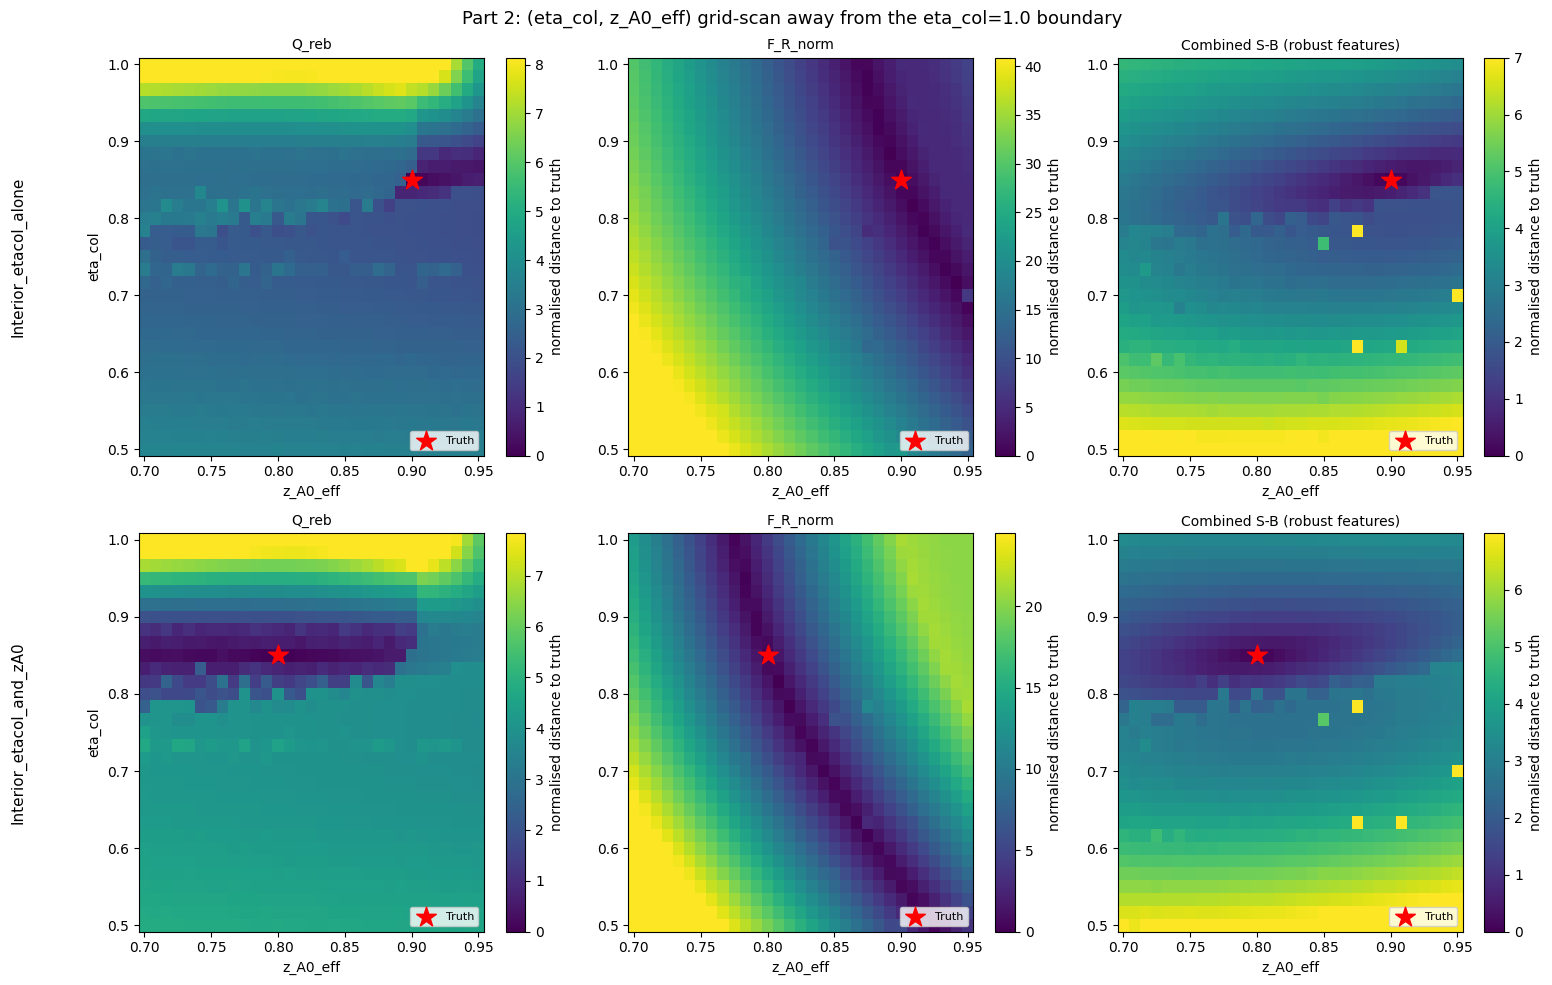

If the combined (robust) panel now shows a small, localised low-distance region near the
star (unlike the boundary-hugging band seen at eta_col=1.0 in nb39), that confirms the
original nominal-point result was a boundary artifact, not a genuine interior degeneracy.


In [7]:
fig, axes = plt.subplots(len(ETACOL_POINTS), 3, figsize=(15.5, 5.0 * len(ETACOL_POINTS)), squeeze=False)
for row, point in enumerate(ETACOL_POINTS):
    truth = point['truth']
    views = etacol_grids[point['name']]
    for col, view in enumerate(['Q_reb', 'F_R_norm', 'robust']):
        g1, g2, dist = views[view]
        ax = axes[row][col]
        vmax = np.nanpercentile(dist, 95)
        im = ax.pcolormesh(g2, g1, dist, shading='auto', cmap='viridis', vmax=vmax)
        ax.scatter([truth[Z_A0_IDX]], [truth[ETA_COL_IDX]], color='red', marker='*', s=220, zorder=10, label='Truth')
        ax.set_xlabel('z_A0_eff'); ax.set_ylabel('eta_col' if col == 0 else '')
        ax.set_title(view if view != 'robust' else 'Combined S-B (robust features)', fontsize=10)
        ax.legend(fontsize=8, loc='lower right')
        fig.colorbar(im, ax=ax, label='normalised distance to truth')
    axes[row][0].annotate(point['name'], xy=(-0.35, 0.5), xycoords='axes fraction', fontsize=11,
                           rotation=90, va='center', ha='center')
fig.suptitle('Part 2: (eta_col, z_A0_eff) grid-scan away from the eta_col=1.0 boundary', fontsize=13)
plt.tight_layout()
fig.savefig(FIGURES / '41_sysII_etacol_zA0_interior_gridscan.png', dpi=170, bbox_inches='tight')
plt.show()
print('If the combined (robust) panel now shows a small, localised low-distance region near the')
print('star (unlike the boundary-hugging band seen at eta_col=1.0 in nb39), that confirms the')
print('original nominal-point result was a boundary artifact, not a genuine interior degeneracy.')

In [8]:
for point in ETACOL_POINTS:
    fim_pair_report(point['truth'], ETA_COL_IDX, Z_A0_IDX, point['name'])

--- Interior_etacol_alone (theta=[1.0, 1.0, 0.8500000238418579, 1.0, 0.8999999761581421]) ---


  compute_summaries (66-D)               seed_offset=   0: corr(cov)=+0.622  [raw info off-diag=-0.678]  I_aa/I_bb=13.40x


  compute_summaries (66-D)               seed_offset= 500: corr(cov)=+0.840  [raw info off-diag=-0.717]  I_aa/I_bb=15.10x


  compute_summaries (66-D)               seed_offset= 999: corr(cov)=+0.859  [raw info off-diag=-0.804]  I_aa/I_bb=21.34x


  subwindow, 9 channels x 6 (108-D)      seed_offset=   0: corr(cov)=+0.819  [raw info off-diag=-0.831]  I_aa/I_bb=24.64x


  subwindow, 9 channels x 6 (108-D)      seed_offset= 500: corr(cov)=+0.809  [raw info off-diag=-0.821]  I_aa/I_bb=23.31x


... (9 outputs left out)

  subwindow, 9 channels x 6 (108-D)      seed_offset= 999: corr(cov)=+0.719  [raw info off-diag=-0.616]  I_aa/I_bb=16.48x


  raw trajectory, 9 channels (1080-D)    seed_offset=   0: corr(cov)=+0.536  [raw info off-diag=-0.497]  I_aa/I_bb=10.18x


  raw trajectory, 9 channels (1080-D)    seed_offset= 500: corr(cov)=+0.514  [raw info off-diag=-0.493]  I_aa/I_bb=9.65x


  raw trajectory, 9 channels (1080-D)    seed_offset= 999: corr(cov)=+0.518  [raw info off-diag=-0.488]  I_aa/I_bb=9.79x


### Verdict -- Part 2

**Not a boundary artifact.** At the interior point (`eta_col=0.85`, well past the
`HEALTHY_THRESHOLDS['eta_col']=0.80` fault line and comfortably inside `[0.50, 1.00]`), the
corrected FIM correlation is `+0.62` to `+0.86` (compute_summaries) and `+0.66` to `+0.76`
(raw trajectory) -- if anything *stronger* than the original boundary-point result
(`+0.76 -> +0.52`), and the grid-scan (`figures/41_sysII_etacol_zA0_interior_gridscan.png`)
shows a real, compact low-distance region centred on the truth, not the boundary-hugging band
seen at `eta_col=1.0`. Both interior variants (`eta_col` perturbed alone, and jointly with
`z_A0_eff`) agree. **`(eta_col, z_A0_eff)` is confirmed as a second, genuine,
representation-robust identifiability limit, independent of the `eta_col=1.0` boundary
concern.** Unlike `(alpha, z_A0_eff)`, this one appears single-signed (consistently positive)
across every point tested so far -- a simpler, more consistent coupling.

---
## Overall synthesis

Once both parts are filled in, update `docs/Manuscript/system_ii_sbc_repair_directions.md`
and `HANDOFF.md` with whichever of the two scenarios laid out there applies:

- **Both couplings confirmed real and boundary-independent:** stop pursuing a training/
  geometry fix (already exhaustively tried across `nb38`/`nb39` Part II). Move to either (a)
  a reduced-dimension posterior over the well-identified subset plus an explicit,
  physically-explained non-identifiability finding for `(alpha, z_A0_eff)` [and possibly
  `(eta_col, z_A0_eff)`], or (b) noting that a reactor-side composition sensor -- not
  currently in either S-A or S-B -- would be the concrete missing instrumentation.
- **`alpha`-nominal tiebreak favours the posterior (positive, weak):** the confound is
  non-monotonic / activates mainly away from nominal -- a more nuanced, scenario-dependent
  story than a blanket limitation.
- **`eta_col` re-test collapses at the interior point:** the original nominal-point result
  was a boundary artifact; only `(alpha, z_A0_eff)` remains a live finding, not `eta_col`.